<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/QNN_DataBreach_Upadhyay2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QNN training-data theft by an untrusted quantum cloud: "Quantum Data Breach" (Upadhyay and Ghosh, 2025) step by step

This notebook re-implements, runs and checks the attack and the defence of

> Suryansh Upadhyay and Swaroop Ghosh,
> "Quantum Data Breach: Reusing Training Dataset by Untrusted Quantum Clouds",
> 26th International Symposium on Quality Electronic Design (ISQED), 2025. https://doi.org/10.1109/ISQED65160.2025.11014467
> (preprint: arXiv:2407.14687, 19 July 2024)

The paper publishes no code, so everything below is written from the method as the paper describes it, with the same
software family it names (PennyLane, scikit-learn). The quantum circuits are simulated locally; no quantum hardware or
cloud account is needed.

**The story in four sentences.** A company trains a quantum neural network (QNN) on a *third-party quantum cloud*. To run
the circuits, the cloud has to see them, and the training data sit inside the circuits as rotation angles. So the cloud can read
the training *inputs* directly; what it lacks is the *labels*, which stay on the user's computer. The paper shows that the cloud
can reconstruct the labels anyway, because it also sees the circuit's measurement results in every training epoch and the
QNN's own predictions converge to the true labels. The stolen, relabelled dataset can then be sold or used to train a clone.

**What the notebook does.**
1. Loads Iris and four 4-class subsets (MNIST, Fashion-MNIST, Kuzushiji-MNIST, Letters), reduces each to 4 or 8 features and scales them to rotation angles.
2. Builds a fast simulator of the paper's QNN (angle encoding, Strongly Entangling Layers, Pauli-Z read-out, 1000 shots), checks it against PennyLane, and a noise model calibrated on the IBM Hanoi backend the paper used.
3. Plays the *victim*: trains the QNN and records exactly what the cloud sees (the encoded angles and the read-outs, epoch by epoch).
4. Plays the *adversary*: reads the training data out of the circuits, infers labels with three voting heuristics (majority, linear weights, exponential weights), and cleans them with iterative k-fold cross-validation (correct or prune suspicious labels).
5. Trains a clone QNN (and classical baselines) on the stolen dataset and compares it with the victim's model.
6. Applies the paper's defence (a masking class and a modified loss) and measures how much label recovery drops.
7. Prints the paper's numbers next to ours with a verdict for every claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs pinned
packages; if Colab asks to restart the session, restart and run all again. `FAST_MODE = True` is a class demo (two 8-qubit
datasets and Iris, reduced sizes, about 10 minutes on a CPU); `FAST_MODE = False` is the full-size run (all five datasets, 700 training
samples and 20 epochs for the 8-qubit sets, 3 seeds for Iris; about 50 minutes on a CPU). The notebook saved in the repository was
executed with the setting written in its configuration cell; the other mode is one edit away.

**What you get at the end.** The paper's five result figures redrawn from our own runs, a table of paper numbers versus our
numbers with a verdict per claim, and a critical reading of what the experiment does and does not show.

## The paper in one page

**Problem.** QML-as-a-Service: users may train QNNs on an untrusted quantum cloud. Training is expensive (hundreds of epochs,
thousands of circuit executions each), so the model *and the training data* are valuable. Earlier work protected circuits
or model weights; this paper is the first to show that the **training dataset itself leaks**.

**Threat model.** The adversary is the cloud provider (white-box access). It sees (a) every circuit submitted, including the
state-preparation (data-loading) part that holds the input features as gate angles, and (b) every measurement result, in
every epoch. It can tell epochs apart and recognise the same data point across epochs (same angles). It does **not** see the
labels, the loss, the optimiser state or the classical post-processing. For the demonstration it is also *assumed* to know the
classical pre-processing (for example PCA), the encoding type (angle encoding) and the qubit mapping.

**Attack.** (1) Read the inputs directly from the encoding circuits. (2) For every data point collect the label implied by the
measurement results in each epoch (class = the measured qubit with the largest Pauli-Z expectation). (3) Combine the epoch labels with
a heuristic: *majority voting*, *weighted majority with linearly increasing weights* (1, 2, 3, ...) or *weighted majority with
exponentially increasing weights* (1, 2, 4, ... up to a "rollover" epoch, the 90th percentile epoch, then constant).
(4) Refine: iterative k-fold cross-validation (k = 5, 7, 10, 15) with an ensemble of RandomForest, LogisticRegression, SVC and MLP;
a point is suspect if *all* classifiers disagree with its label; it is relabelled if the ensemble confidence is above 0.8, otherwise pruned.

**Victim model.** Angle encoding with RZ gates (features scaled to a rotation range), Strongly Entangling Layers (6 layers for
the 4-qubit Iris model, 12 for the 8-qubit models), Pauli-Z expectation values, 1000 shots, Adam, learning rate 1e-3, 30 epochs,
batch size 32 (16 for Iris). Noiseless runs on PennyLane `lightning.qubit`, noisy runs on Qiskit's `Fake27QPulseV1` (IBM Hanoi).

**Data.** MNIST-4 (digits 0-3), Fashion-4 (classes 6-9), Kuzushiji-4 (classes 3, 5, 6, 9), Letters-4 (classes 1-4), each reduced
from 28x28 to 8 features by a convolutional autoencoder, 1000 samples (700 train / 300 test); Iris, 4 features, 3 classes,
156 samples (90 train / 66 test).

**Defence.** (1) *Masking class*: train with one extra class (4 instead of 3 for Iris, 5 instead of 4 for the others) and measure
all qubits, so the adversary cannot tell the number of classes or which qubits carry the labels. (2) *Modified loss*
`L_total = L_correct + alpha * L_adversary`, where `L_adversary` is a cross-entropy against deliberately wrong labels when all
qubits are read; `alpha = 1`.

**Claims (numbers from the text; the figures are not machine-readable).**

| # | Claim | Paper value |
|---|---|---|
| C1 | Label recovery, noiseless victims at about 90 % training accuracy (Fig. 2), mean over 5 datasets | majority 86 %, linear 90 %, exponential 92 % |
| C2 | Label recovery on noisy Iris versus victim training accuracy (Fig. 3), averaged over the accuracy range | majority 70 %, linear 76 %, exponential 80 % |
| C3 | k-fold refinement, victims at about 90 % (Fig. 4): reduction of wrong labels | Fashion 18 %, Kuzu 22 %, Letters 35 %, MNIST 70 %, Iris 20 %; mean about 30 % |
| C4 | Refinement pruning cost | Fashion 1.5 %, Kuzu 2 %, Letters 3.5 %, MNIST 1.5 %, Iris 2 %; mean about 2 % |
| C5 | Clone trained on stolen Iris data, noisy backend, 15 epochs (Fig. 5) | victim data: train 93 % / test 88 %; stolen data: train 90 % / test 86 % |
| C6 | Abstract: about 90 % of the labels extracted correctly; clone accuracy about 90 % | about 90 % |
| C7 | Without defence the exponential heuristic labels nearly everything (Fig. 6) | about 100 % for Fashion, Kuzu, Letters, Iris; about 90 % for MNIST |
| C8 | With the defence the adversary's label accuracy (Fig. 6) | Fashion 20 %, Kuzu 40 %, Letters 30 %, MNIST 10 %, Iris 25 %; mean reduction about 70 % |
| C9 | Cost of the defence for the user | training accuracy drops by about 2 % |
| C10 | The state-preparation circuit (the inputs) is "relatively easy to identify and extract" | qualitative |

### What follows the paper and what had to be chosen

The paper is a six-page workshop-style paper; many settings are not stated. Every choice below is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Feature reduction | convolutional autoencoder to 8 features (taken from the QOC pre-processing, ref. [33]) | **PCA to 8 components** fitted on the training split only (no deep-learning framework needed); then MinMax scaling to [0, pi] fitted on the training split, test angles clipped |
| Letters-4 dataset | EMNIST-style letters 1-4 (a-d), 28x28 | **UCI/OpenML "letter" dataset** (16 handcrafted features), letters A-D, PCA to 8 components (EMNIST is not on OpenML) |
| Kuzushiji-4, Fashion-4, MNIST-4 | classes (3, 5, 6, 9), (6, 7, 8, 9), (0, 1, 2, 3) | same classes, from OpenML (`Kuzushiji-MNIST`, `Fashion-MNIST`, `mnist_784`); 1000 samples, 700/300 (FAST: 320, 224/96) |
| Iris | 156 samples, 90 train / 66 test | Iris has 150 samples: **90 train / 60 test**, stratified |
| Data-loading gate | "angle encoding with the RZ gate" | **Hadamard followed by RZ(x)** on each wire. A bare RZ acting on the all-zero starting state is only a global phase and encodes nothing, so a Hadamard (or an RX/RY) must precede it; the paper does not say which |
| Ansatz | Strongly Entangling Layers, 6 layers (Iris) / 12 (others) | same (PennyLane layout: `Rot` on every wire, then a ring of CNOTs with range `l mod (n-1) + 1`), weights uniform in [0, 2 pi) |
| Class read-out | Pauli-Z expectation values, then a (softmax) layer; class = qubit | class k = qubit k; **softmax applied directly to the C Pauli-Z values, no trainable classical layer**, so the adversary's `argmax` over read-outs equals the user's prediction |
| Shots | 1000 | 1000: each qubit's marginal is sampled exactly (binomial) from the simulated expectation value; the gradient ignores shot noise |
| Optimiser | Adam, lr 1e-3, 30 epochs, batch 32 (16 Iris) | Adam, **lr 1e-2** (with lr 1e-3 our read-out reaches only about 78 % training accuracy on Iris in 30 epochs, see the check in Section 3), batch 32 (16 Iris), epochs: 20 for the attack runs (as in Fig. 2 and Fig. 4), 15 for the clones (as in Fig. 5) |
| Noisy backend | Qiskit `Fake27QPulseV1` (IBM Hanoi) trained with `qiskit.aer` | **Own density-matrix simulator** with depolarising noise and read-out error whose rates are read from `FakeHanoiV2` (the successor of `Fake27QPulseV1`); used for the **4-qubit Iris model only**. The 8-qubit models are trained noiselessly (a noisy 8-qubit, 12-layer density-matrix run is too slow on a CPU) and stopped at about 90 % training accuracy, which is the condition the paper states for its noisy Fig. 4 |
| Training time per run | not stated | 8-qubit run with 700 samples: about 5 s per epoch on a CPU |
| Adversary's knowledge | pre-processing, encoding type and qubit mapping known | same assumption; in addition the adversary measures the same qubits the user does |
| Refinement iterations | "iterative", no count | at most 3 rounds, stop early when nothing changes; classifier hyper-parameters are scikit-learn defaults except a smaller forest/MLP for speed |
| Which label wins for confidence | "confidence of the predicted label" | ensemble-mean probability of the ensemble's most probable class, threshold 0.8 |
| Defence: adversarial labels | "adversarial labels", not specified | for every training point a *fixed random wrong* qubit index (never the point's own class qubit), drawn once per run; masking class and user qubits chosen at random once per run |
| Defence: how the adversary scores | "correct label prediction accuracy" | **strict** score (adversary's class index equals the true class index) and a **permutation-invariant** score (best one-to-one matching of adversary labels to classes, an adversary who only wants a clustering) |
| Seeds | not stated | `SEED = 42`; Iris repeated over 3 seeds (2 in FAST mode), the 8-qubit sets use one seed (cost) |
| Quantum clones of the 8-qubit sets | not run (only Iris, Fig. 5) | full run only: 10 epochs on the original and on the stolen set; classical clones (RandomForest, SVC) always |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy and matplotlib.
# The pip line runs on Colab (or wherever PennyLane / qiskit-ibm-runtime are missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
_missing = [m for m in ("pennylane", "autograd", "qiskit_ibm_runtime") if importlib.util.find_spec(m) is None]
if IN_COLAB or _missing:
    %pip install -q "pennylane==0.45.1" "pennylane-lightning==0.45.0" "qiskit==2.5.2" "qiskit-ibm-runtime==0.50.0" "autograd==1.8.0"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane / autograd / qiskit-ibm-runtime already present; skipping pip install.")

PennyLane / autograd / qiskit-ibm-runtime already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE  = False     # True: class demo (about 10 minutes on a CPU). False: full-size run of the paper's setting (about 50 min on a CPU).
SEED       = 42           # CHOICE: the paper gives no seed
IBM_TOKEN  = ""           # not needed: everything is simulated locally (kept for convention; no real-hardware cell here)
DATA_DIR   = "qc197_data" # where the downloaded datasets are cached (relative to the working directory)

# --- data sizes (paper: 1000 samples per 4-class set, 700 train / 300 test; Iris 90 / 60) ---
if FAST_MODE:
    BIG_DATASETS     = ["mnist", "fashion"]      # the full run adds "kuzu" and "letters"
    N_TOTAL, N_TRAIN = 320, 224          # per 4-class set (the paper uses 1000 / 700)
    EPOCHS_ATTACK    = 8                 # epochs the 8-qubit victims train (paper: 20, Fig. 2/4)
    EPOCHS_CLONE_BIG = 0                 # 0 = skip quantum clones of the 8-qubit sets (classical clones still run)
    SEEDS_IRIS       = [42, 43]
    EPOCHS_IRIS, EPOCHS_CLONE_IRIS = 12, 10          # paper: 20 and 15
    SWEEP_EPOCHS, SWEEP_NOISE, SWEEP_SEEDS = [2, 6, 12], [1.0, 8.0], [42]
    ALPHAS           = [1.0]
else:
    BIG_DATASETS     = ["mnist", "fashion", "kuzu", "letters"]
    EPOCHS_IRIS, EPOCHS_CLONE_IRIS = 20, 15
    N_TOTAL, N_TRAIN = 1000, 700
    EPOCHS_ATTACK    = 20
    EPOCHS_CLONE_BIG = 10
    SEEDS_IRIS       = [42, 43, 44]
    SWEEP_EPOCHS, SWEEP_NOISE, SWEEP_SEEDS = [1, 2, 3, 5, 8, 12, 20], [1.0, 4.0, 10.0], [42, 43]
    ALPHAS           = [0.0, 1.0, 3.0]

SEEDS_BIG    = [SEED]        # one seed for the 8-qubit sets (about 8 s per epoch)
N_QUBITS     = {"iris": 4, **{d: 8 for d in ["mnist", "fashion", "kuzu", "letters"]}}
N_LAYERS     = {"iris": 6, **{d: 12 for d in N_QUBITS if d != "iris"}}     # paper: 6 SEL layers (Iris), 12 (others)
BATCH        = {"iris": 16, **{d: 32 for d in N_QUBITS if d != "iris"}}     # paper: 16 (Iris), 32 (others)
LR           = 1e-2          # CHOICE: paper says 1e-3; see Section 4 for the check with 1e-3
LR_PAPER     = 1e-3
SHOTS        = 1000          # paper: 1000 shots

# --- attack settings from the paper ---
KFOLDS       = (5, 7, 10, 15)   # paper: k = 5, 7, 10, 15
CONF_THR     = 0.8              # paper: confidence threshold 0.8
REFINE_ROUNDS = 3               # CHOICE: the paper says "iterative" without a count
ROLLOVER_PCT = 90               # paper: 90th-percentile epoch is the rollover of the exponential weights
ALPHA_DEFENCE = 1.0             # paper: alpha = 1

In [3]:
import os, time, warnings, itertools, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import autograd, autograd.numpy as anp
from autograd import value_and_grad
from autograd.tracer import getval
import scipy
from scipy.optimize import linear_sum_assignment
import sklearn
from sklearn.datasets import fetch_openml, load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
import pennylane as qml

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
print("numpy", np.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__, "| pennylane", qml.__version__, "| autograd", importlib.metadata.version("autograd"))

numpy 2.5.4 | scipy 1.18.1 | scikit-learn 1.9.1 | pennylane 0.45.1 | autograd 1.8.0


## 1. Data: Iris and four 4-class subsets, reduced to one feature per qubit

A QNN with angle encoding needs one rotation angle per qubit, so each sample must be squeezed into 4 (Iris) or 8 (the others)
numbers. The paper uses a convolutional autoencoder; we use **PCA** (a linear autoencoder), which needs no deep-learning
framework and is fitted on the **training split only** (no test-set leakage). The features are then min-max scaled to the angle range
[0, pi] (also fitted on the training split; test angles are clipped).

These 4-/8-number vectors are *exactly* what the cloud will later read out of the circuits, so the PCA is part of the victim's
secret pre-processing (the adversary is assumed to know it).

In [4]:
# CHOICE: OpenML sources (the paper's exact pre-processed arrays from its ref. [33] are not public here).
SPEC = {
    "iris":    dict(title="Iris",         classes=None),
    "mnist":   dict(title="MNIST-4",      openml=("mnist_784", {"version": 1}),      classes=["0", "1", "2", "3"]),
    "fashion": dict(title="Fashion-4",    openml=("Fashion-MNIST", {"version": 1}),  classes=["6", "7", "8", "9"]),
    "kuzu":    dict(title="Kuzushiji-4",  openml=("Kuzushiji-MNIST", {}),            classes=["3", "5", "6", "9"]),
    "letters": dict(title="Letters-4",    openml=("letter", {"version": 1}),         classes=["A", "B", "C", "D"]),   # CHOICE: UCI letter data, 16 features
}

def load_raw(name):
    """Return (X, y) for the 4-class subset, cached as a small .npz in DATA_DIR."""
    if name == "iris":
        X, y = load_iris(return_X_y=True); return X, y
    cache = os.path.join(DATA_DIR, f"{name}_subset.npz")
    if os.path.exists(cache):
        z = np.load(cache); return z["X"].astype(float), z["y"]
    oname, kw = SPEC[name]["openml"]
    X, y = fetch_openml(oname, as_frame=False, return_X_y=True, data_home=os.path.join(DATA_DIR, "openml"), parser="auto", **kw)
    classes = SPEC[name]["classes"]
    m = np.isin(y.astype(str), classes)
    X = X[m].astype(float); y = np.array([classes.index(v) for v in y[m].astype(str)])
    np.savez_compressed(cache, X=X.astype(np.float32 if name == "letters" else np.uint8), y=y)
    return X, y

def make_split(name, seed, n_total=None, n_train=None):
    """Stratified balanced subset -> train/test -> StandardScaler -> PCA(n_qubits) -> MinMax(0, pi); everything fitted on train only."""
    n_total = N_TOTAL if n_total is None else n_total
    n_train = N_TRAIN if n_train is None else n_train
    X, y = load_raw(name)
    nq = N_QUBITS[name]
    if name == "iris":
        Xtr, Xte, ytr, yte = train_test_split(X, y, train_size=90, test_size=60, stratify=y, random_state=seed)
    else:
        r = np.random.default_rng(seed)
        C = len(np.unique(y)); per = n_total // C
        idx = np.concatenate([r.choice(np.where(y == c)[0], per, replace=False) for c in range(C)])
        Xtr, Xte, ytr, yte = train_test_split(X[idx], y[idx], train_size=n_train, test_size=n_total - n_train, stratify=y[idx], random_state=seed)
    sc = StandardScaler().fit(Xtr)
    pca = PCA(n_components=nq, random_state=seed).fit(sc.transform(Xtr))
    Ztr, Zte = pca.transform(sc.transform(Xtr)), pca.transform(sc.transform(Xte))
    mm = MinMaxScaler((0, np.pi)).fit(Ztr)
    return dict(name=name, Atr=mm.transform(Ztr), Ate=np.clip(mm.transform(Zte), 0, np.pi), ytr=ytr, yte=yte,
                Xtr_raw=Xtr, Xte_raw=Xte, sc=sc, pca=pca, mm=mm, n_qubits=nq, n_classes=len(np.unique(y)), seed=seed)

_t = time.time()
SPLITS = {}
rows = []
for ds in ["iris"] + BIG_DATASETS:
    SPLITS[(ds, SEED)] = make_split(ds, SEED)
    s = SPLITS[(ds, SEED)]
    rows.append(dict(dataset=SPEC[ds]["title"], raw_features=s["Xtr_raw"].shape[1], qubits=s["n_qubits"], classes=s["n_classes"],
                     train=len(s["ytr"]), test=len(s["yte"]), pca_explained_variance=round(float(s["pca"].explained_variance_ratio_.sum()), 3)))
display(pd.DataFrame(rows))
print(f"data ready in {time.time()-_t:.0f} s")

,dataset,raw_features,qubits,classes,train,test,pca_explained_variance
0,Iris,4,4,3,90,60,1.000
1,MNIST-4,784,8,4,700,300,0.378
2,Fashion-4,784,8,4,700,300,0.603
3,Kuzushiji-4,784,8,4,700,300,0.356
4,Letters-4,16,8,4,700,300,0.900


data ready in 2 s


## 2. A fast simulator of the paper's QNN (and a check against PennyLane)

The paper's QNN is: for every qubit a Hadamard and `RZ(x_i)` (angle encoding), then PennyLane's **Strongly Entangling Layers**
(a general rotation `Rot(phi, theta, omega)` on every qubit followed by a ring of CNOTs), then Pauli-Z expectation values.

PennyLane's own differentiable simulators need about one second per mini-batch gradient for 8 qubits and 12 layers. We need
many training runs (several datasets, epochs and seeds), so we write the *same* circuit as plain numpy linear algebra
(`autograd` supplies the gradients). Two versions:

* `SEL`: noiseless state vector, 8 qubits, about 0.3 s per mini-batch gradient.
* `SELNoisy`: density matrix with **depolarising noise** after every rotation layer and every CNOT, plus a symmetric **read-out
  error**. It is used for the 4-qubit Iris model only (a 12-layer 8-qubit density matrix would be far too slow).

The cell after the code verifies both against PennyLane (the paper's `lightning.qubit` and `default.mixed`): the differences
must be at floating-point level.

In [5]:
# Fast, differentiable simulators written with numpy + autograd (see the explanation above).
def rot_mats(w):
    """w: (n,3) -> (n,2,2) complex Rot(phi,theta,omega) = RZ(omega) RY(theta) RZ(phi)"""
    phi, th, om = w[:, 0], w[:, 1], w[:, 2]
    c, s = anp.cos(th / 2), anp.sin(th / 2)
    a = anp.exp(-0.5j * (phi + om)) * c
    b = -anp.exp(0.5j * (phi - om)) * s
    cc = anp.exp(-0.5j * (phi - om)) * s
    d = anp.exp(0.5j * (phi + om)) * c
    return anp.stack([anp.stack([a, b], -1), anp.stack([cc, d], -1)], -2)

def kron_all(mats):
    out = mats[0]
    for m in mats[1:]:
        k = out.shape[0]
        out = anp.einsum('ab,cd->acbd', out, m).reshape(k * 2, k * 2)
    return out

def cnot_ring_perm(n, r):
    """index permutation: new_state[:, j] = old_state[:, perm[j]] for CNOT(i,(i+r)%n) for i in 0..n-1 (sequential)."""
    dim = 2 ** n
    idx = np.arange(dim)
    # a basis state |b0..b(n-1)> (wire 0 = most significant). Map basis index through the CNOT sequence.
    def bits(k): return [(k >> (n - 1 - q)) & 1 for q in range(n)]
    def idx_of(b): return sum(bit << (n - 1 - q) for q, bit in enumerate(b))
    dest = np.zeros(dim, dtype=int)
    for k in range(dim):
        b = bits(k)
        for i in range(n):
            t = (i + r) % n
            if b[i]: b[t] ^= 1
        dest[k] = idx_of(b)
    perm = np.zeros(dim, dtype=int)
    perm[dest] = np.arange(dim)  # new[j] = old[perm[j]]
    return perm

def z_signs(n):
    dim = 2 ** n
    S = np.zeros((dim, n))
    for k in range(dim):
        for q in range(n):
            S[k, q] = 1 - 2 * ((k >> (n - 1 - q)) & 1)
    return S

class SEL:
    def __init__(self, n, L):
        self.n, self.L = n, L
        self.perms = [cnot_ring_perm(n, (l % (n - 1)) + 1) for l in range(L)]
        self.S = z_signs(n)

    def init_state(self, X):
        """H then RZ(x) on each wire: qubit state (e^{-ix/2}, e^{ix/2})/sqrt2 ; X (B,n)"""
        B, n = X.shape
        q = anp.stack([anp.exp(-0.5j * X), anp.exp(0.5j * X)], -1) / np.sqrt(2)  # (B,n,2)
        st = q[:, 0, :]
        for i in range(1, n):
            st = anp.einsum('bk,bj->bkj', st, q[:, i, :]).reshape(B, -1)
        return st

    def expvals(self, X, W):
        st = self.init_state(X)
        B, n = st.shape[0], self.n
        for l in range(self.L):
            R = rot_mats(W[l])                                   # one 2x2 rotation per wire
            for q in range(n):                                   # apply it to wire q only (wire 0 = most significant bit)
                s = st.reshape(B, 2 ** q, 2, 2 ** (n - q - 1))
                st = anp.einsum('ij,bajc->baic', R[q], s).reshape(B, -1)
            st = st[:, self.perms[l]]                            # ring of CNOTs = a fixed permutation of the amplitudes
        p = anp.abs(st) ** 2
        return p @ self.S

class SELNoisy:
    """Density-matrix version of the same circuit with depolarising noise.
    p1: per-qubit depolarising probability after every single-qubit Rot layer,
    p2: two-qubit depolarising probability after every CNOT, ro: symmetric readout flip probability.
    Everything that does not depend on the weights is pre-multiplied into constant 'superoperators'
    (matrices acting on vec(rho)), so training stays fast."""
    def __init__(self, n, L, p1=0.0, p2=0.0, ro=0.0):
        import itertools
        self.n, self.L, self.p1, self.p2, self.ro = n, L, p1, p2, ro
        dim = self.dim = 2 ** n
        self.S = z_signs(n)
        Xm = np.array([[0, 1], [1, 0]], dtype=complex); Ym = np.array([[0, -1j], [1j, 0]]); Zm = np.diag([1, -1]).astype(complex)
        P = [np.eye(2, dtype=complex), Xm, Ym, Zm]
        def full(op_by_q):
            M = np.array([[1.0 + 0j]])
            for q in range(n):
                M = np.kron(M, op_by_q.get(q, P[0]))
            return M
        def depol_superop(qs, prob):
            S = np.zeros((dim * dim, dim * dim), dtype=complex)
            for combo in itertools.product(range(4), repeat=len(qs)):
                Pm = full({q: P[a] for q, a in zip(qs, combo)})
                S += np.kron(Pm, Pm.conj())
            S /= 4 ** len(qs)
            return (1 - prob) * np.eye(dim * dim) + prob * S
        N1 = np.eye(dim * dim, dtype=complex)
        if p1 > 0:
            for q in range(n):
                N1 = depol_superop([q], p1) @ N1
        self.C = []
        for l in range(L):
            r = (l % (n - 1)) + 1
            M = N1.copy()
            for i in range(n):
                c, t = i, (i + r) % n
                Pc = np.zeros((dim, dim))
                for k in range(dim):
                    b = [(k >> (n - 1 - q)) & 1 for q in range(n)]
                    if b[c]: b[t] ^= 1
                    Pc[sum(bit << (n - 1 - q) for q, bit in enumerate(b)), k] = 1
                M = np.kron(Pc, Pc) @ M
                if p2 > 0:
                    M = depol_superop([c, t], p2) @ M
            self.C.append(M)

    def expvals(self, X, W):
        n, dim = self.n, self.dim
        B = X.shape[0]
        q = anp.stack([anp.exp(-0.5j * X), anp.exp(0.5j * X)], -1) / np.sqrt(2)
        st = q[:, 0, :]
        for i in range(1, n):
            st = anp.einsum('bk,bj->bkj', st, q[:, i, :]).reshape(B, -1)
        v = anp.einsum('bi,bj->bij', st, anp.conj(st)).reshape(B, dim * dim)
        for l in range(self.L):
            K = kron_all(rot_mats(W[l]))
            KK = anp.einsum('ab,cd->acbd', K, anp.conj(K)).reshape(dim * dim, dim * dim)
            M = self.C[l] @ KK
            v = v @ M.T
        rho = v.reshape(B, dim, dim)
        p = anp.real(rho[:, np.arange(dim), np.arange(dim)])
        return (p @ self.S) * (1 - 2 * self.ro)


In [6]:
# ---- check our simulators against PennyLane (the paper's lightning.qubit; default.mixed for the noisy one) ----
def pl_expvals(n, L, X, W, device="lightning.qubit"):
    dev = qml.device(device, wires=n)
    @qml.qnode(dev)
    def circ(x, w):
        for i in range(n):
            qml.Hadamard(wires=i); qml.RZ(x[..., i], wires=i)        # angle-encoding layer
        qml.StronglyEntanglingLayers(w, wires=range(n))
        return [qml.expval(qml.PauliZ(i)) for i in range(n)]
    return np.stack([np.array(circ(x, W)) for x in X])

chk = np.random.default_rng(1)
for (n, L) in [(4, 6), (8, 12)]:
    W = chk.uniform(0, 2 * np.pi, (L, n, 3)); X = chk.uniform(0, np.pi, (3, n))
    d = np.abs(SEL(n, L).expvals(X, W) - pl_expvals(n, L, X, W)).max()
    print(f"noiseless {n} qubits, {L} layers: max |ours - PennyLane lightning.qubit| = {d:.1e}")

# noisy check: depolarising channels written as Kraus Pauli sums for PennyLane's default.mixed
n, L, p1, p2 = 3, 2, 0.01, 0.03
W = chk.uniform(0, 2 * np.pi, (L, n, 3)); X = chk.uniform(0, np.pi, (2, n))
Pm = [np.eye(2), np.array([[0, 1], [1, 0]]), np.array([[0, -1j], [1j, 0]]), np.diag([1, -1])]
KR2 = [np.sqrt((1 - p2 + p2 / 16) if (a == 0 and b == 0) else p2 / 16) * np.kron(Pm[a], Pm[b]) for a, b in itertools.product(range(4), repeat=2)]
@qml.qnode(qml.device("default.mixed", wires=n))
def circ_noisy(x, w):
    for i in range(n):
        qml.Hadamard(wires=i); qml.RZ(x[i], wires=i)
    for l in range(L):
        for i in range(n): qml.Rot(*w[l, i], wires=i)
        for i in range(n): qml.DepolarizingChannel(3 * p1 / 4, wires=i)      # PennyLane's p is 3/4 of the 'mix with I/2' probability
        r = (l % (n - 1)) + 1
        for i in range(n):
            qml.CNOT(wires=[i, (i + r) % n]); qml.QubitChannel(KR2, wires=[i, (i + r) % n])
    return [qml.expval(qml.PauliZ(i)) for i in range(n)]
ref = np.stack([np.array(circ_noisy(x, W)) for x in X])
print(f"noisy {n} qubits, {L} layers: max |ours - PennyLane default.mixed| = {np.abs(SELNoisy(n, L, p1, p2, 0).expvals(X, W) - ref).max():.1e}")

noiseless 4 qubits, 6 layers: max |ours - PennyLane lightning.qubit| = 5.0e-16
noiseless 8 qubits, 12 layers: max |ours - PennyLane lightning.qubit| = 2.4e-16
noisy 3 qubits, 2 layers: max |ours - PennyLane default.mixed| = 2.7e-14


### Noise level taken from the IBM Hanoi backend

The paper's noisy runs use Qiskit's `Fake27QPulseV1`, a snapshot of the 27-qubit IBM Hanoi device with real calibration data.
That class is not shipped with the current Qiskit 2.x stack; its successor `FakeHanoiV2` carries the same calibration. We read three numbers from it:
the **median CNOT error**, the **mean single-qubit (`sx`) error** and the **mean read-out error**, and we transpile one copy of
our 4-qubit circuit to the device to count how many CNOTs the heavy-hex connectivity really needs (SWAP overhead). The
resulting per-gate depolarising probabilities define `SELNoisy`. This is an *approximation of a hardware noise model* (depolarising
instead of the full gate-by-gate noise model of `qiskit-aer`), chosen because it can be trained with exact gradients on a CPU.

In [7]:
# CHOICE: calibrate a depolarising + read-out noise model on FakeHanoiV2 (successor of the paper's Fake27QPulseV1).
FALLBACK = dict(p1=9e-4, p2=0.0127, ro=0.018)      # values obtained from FakeHanoiV2 when this notebook was written
def calibrate_from_hanoi(n=4, L=6, seed=SEED):
    from qiskit import QuantumCircuit, transpile
    from qiskit_ibm_runtime.fake_provider import FakeHanoiV2
    be = FakeHanoiV2(); tg = be.target
    cx = [p.error for p in tg["cx"].values() if p is not None and p.error is not None]
    sx = [p.error for p in tg["sx"].values() if p is not None and p.error is not None]
    ro = [p.error for p in tg["measure"].values() if p is not None and p.error is not None]
    r = np.random.default_rng(seed); qc = QuantumCircuit(n); logical = 0
    for i in range(n): qc.h(i); qc.rz(float(r.uniform(0, 3)), i)
    for l in range(L):
        for i in range(n): qc.rz(float(r.uniform(0, 6)), i); qc.ry(float(r.uniform(0, 6)), i); qc.rz(float(r.uniform(0, 6)), i)
        for i in range(n): qc.cx(i, (i + l % (n - 1) + 1) % n); logical += 1
    ratio = transpile(qc, be, optimization_level=1, seed_transpiler=seed).count_ops().get("cx", 0) / logical
    # error rate r -> depolarising probability p = r * d^2/(d^2-1) (d = 2 for one qubit, 4 for two qubits)
    return dict(p1=2 * np.mean(sx) * 4 / 3, p2=float(np.median(cx)) * ratio * 16 / 15, ro=float(np.mean(ro))), dict(
        median_cx_error=float(np.median(cx)), mean_sx_error=float(np.mean(sx)), mean_readout_error=float(np.mean(ro)), cx_overhead=ratio)
try:
    NOISE, hanoi_info = calibrate_from_hanoi()
    print("FakeHanoiV2 calibration:", {k: round(v, 5) for k, v in hanoi_info.items()})
except Exception as e:
    NOISE = FALLBACK; print("FakeHanoiV2 not available here (", type(e).__name__, "), using stored values")
print("noise model: per-qubit depolarising after each Rot layer p1 = %.2e, two-qubit depolarising after each CNOT p2 = %.4f, read-out flip = %.3f" % (NOISE["p1"], NOISE["p2"], NOISE["ro"]))

_SIM_CACHE = {}
def get_sim(ds, noise_mult=0.0):
    """noise_mult = 0: noiseless state vector; otherwise the Hanoi-calibrated density-matrix model scaled by noise_mult (4-qubit Iris only)."""
    key = (ds, float(noise_mult))
    if key not in _SIM_CACHE:
        n, L = N_QUBITS[ds], N_LAYERS[ds]
        if noise_mult == 0: _SIM_CACHE[key] = SEL(n, L)
        else:
            assert ds == "iris", "noisy density-matrix simulation is only used for the 4-qubit Iris model"
            _SIM_CACHE[key] = SELNoisy(n, L, NOISE["p1"] * noise_mult, min(NOISE["p2"] * noise_mult, 0.5), min(NOISE["ro"] * noise_mult, 0.45))
    return _SIM_CACHE[key]

FakeHanoiV2 calibration: {'median_cx_error': 0.00633, 'mean_sx_error': 0.00022, 'mean_readout_error': 0.01809, 'cx_overhead': 1.875}
noise model: per-qubit depolarising after each Rot layer p1 = 5.93e-04, two-qubit depolarising after each CNOT p2 = 0.0127, read-out flip = 0.018


## 3. The victim trains a QNN on the untrusted cloud, and the cloud keeps a log

The training loop below is the *user's* program. At every optimisation step a mini-batch of circuits goes to the cloud and the
cloud returns the Pauli-Z read-outs of all qubits. The user turns the read-outs of the class qubits into a softmax and a
cross-entropy loss **locally** (the labels never leave the user's computer), and Adam updates the 36 to 288 circuit angles.

Two details matter for the attack:

* Each circuit *contains the training sample* (its `RZ` angles). The cloud sees it.
* Each read-out is a noisy estimate (1000 shots, plus hardware noise for Iris). The class implied by the read-outs of a point
  is therefore the QNN's *current prediction* for that point, which is poor in early epochs and good in late epochs.

`train_qnn` returns, next to the trained weights, the **cloud log**: for every executed circuit, the epoch, the encoded angles and
the read-outs. The `idx` column is only there so that *we* can score the attack afterwards; the adversary never sees it.

In [8]:
def shot_noise(ev, shots, r):
    """Sample each qubit's Z marginal with `shots` shots: <Z> = 1 - 2*(#ones/shots)."""
    p1 = np.clip((1 - ev) / 2, 0, 1)
    return 1 - 2 * r.binomial(shots, p1) / shots

def ce_loss(logits, Y):
    """softmax cross-entropy (mean over the batch); Y is one-hot."""
    mx = np.max(getval(logits), axis=1, keepdims=True)
    lse = anp.log(anp.sum(anp.exp(logits - mx), axis=1)) + mx[:, 0]
    return anp.mean(lse - anp.sum(logits * Y, axis=1))

def train_qnn(sim, A_tr, y_tr, A_te, y_te, n_classes, epochs, lr, bs, seed, meas_qubits=None, adv=None, shots=SHOTS):
    """Adam training of the QNN. Class k is read from qubit meas_qubits[k] (default: qubit k).
    adv (defence): dict(alpha, qubits, y_adv) adds alpha * CE(read-outs of ALL measured qubits, adversarial labels).
    Returns weights, the cloud log and the training history."""
    r = np.random.default_rng(seed)
    n, L = sim.n, sim.L
    W = r.uniform(0, 2 * np.pi, (L, n, 3))                    # CHOICE: PennyLane's default SEL initialisation range
    m1, m2, t = np.zeros_like(W), np.zeros_like(W), 0
    q_user = list(range(n_classes)) if meas_qubits is None else list(meas_qubits)
    onehot, N = np.eye(n_classes)[y_tr], len(A_tr)
    log = dict(epoch=[], idx=[], ang=[], ev=[])
    hist = dict(train_acc=[], test_acc=[], loss=[])
    for ep in range(epochs):
        perm, losses, ok = r.permutation(N), [], 0
        for s in range(0, N, bs):
            b = perm[s:s + bs]
            cap = {}
            def loss_fn(Wt):
                ev = sim.expvals(A_tr[b], Wt)                    # what the quantum cloud computes
                evv = getval(ev)
                evn = ev + (shot_noise(evv, shots, r) - evv)      # finite-shot read-out (noise is a constant offset for the gradient)
                cap["ev"] = getval(evn)
                total = ce_loss(evn[:, q_user], onehot[b])        # L_correct
                if adv is not None:                              # defence: L_total = L_correct + alpha * L_adversary
                    Ya = np.eye(len(adv["qubits"]))[adv["y_adv"][b]]
                    total = total + adv["alpha"] * ce_loss(evn[:, adv["qubits"]], Ya)
                return total
            lval, g = value_and_grad(loss_fn)(W)
            t += 1
            m1 = 0.9 * m1 + 0.1 * g; m2 = 0.999 * m2 + 0.001 * g * g
            W = W - lr * (m1 / (1 - 0.9 ** t)) / (np.sqrt(m2 / (1 - 0.999 ** t)) + 1e-8)
            losses.append(float(lval)); ok += int((cap["ev"][:, q_user].argmax(1) == y_tr[b]).sum())
            log["epoch"].append(np.full(len(b), ep)); log["idx"].append(b); log["ang"].append(A_tr[b]); log["ev"].append(cap["ev"])
        hist["train_acc"].append(ok / N); hist["loss"].append(float(np.mean(losses)))
        ev_te = shot_noise(sim.expvals(A_te, W), shots, r)
        hist["test_acc"].append(float((ev_te[:, q_user].argmax(1) == y_te).mean()))
    log = {k: np.concatenate(v) for k, v in log.items()}
    return W, log, hist

### Sanity check of the training loop, and the learning-rate choice

First a quick check on Iris (noiseless): the paper's learning rate `1e-3` versus our `1e-2`, 30 epochs, batch 16. With the
class qubits' Pauli-Z values fed straight into a softmax (values are confined to [-1, 1], so the logits are small), `1e-3` learns slowly.

In [9]:
s_iris = SPLITS[("iris", SEED)]
rows = []
for lr in (LR_PAPER, LR):
    t0 = time.time()
    W, log, h = train_qnn(get_sim("iris"), s_iris["Atr"], s_iris["ytr"], s_iris["Ate"], s_iris["yte"], 3, 30, lr, BATCH["iris"], SEED)
    rows.append(dict(lr=lr, epochs=30, final_train_acc=round(h["train_acc"][-1], 3), final_test_acc=round(h["test_acc"][-1], 3), seconds=round(time.time() - t0, 1)))
LR_CHECK = pd.DataFrame(rows); display(LR_CHECK)
print(f"-> paper: lr 1e-3 and about 93 % training accuracy for the victim (noisy Iris). CHOICE: we use lr = {LR:g}.")

,lr,epochs,final_train_acc,final_test_acc,seconds
0,0.001,30,0.756,0.783,5.8
1,0.010,30,0.933,0.817,3.8


-> paper: lr 1e-3 and about 93 % training accuracy for the victim (noisy Iris). CHOICE: we use lr = 0.01.


## 4. What the cloud sees: the training data are readable straight from the circuits

Before any label inference, **the inputs are already stolen**: the data-loading `RZ` gates carry them as plain numbers. The paper
calls this "relatively easy to identify and extract" and assumes the adversary knows the encoding type, the qubit mapping and the
classical pre-processing. We play it out on a MNIST-4 victim:

1. Train the 8-qubit victim (this is the longest cell of the section).
2. Pick a few of the circuits in the cloud log, build the actual PennyLane circuit (a `QuantumScript`), and read the angles
   of the `RZ` gates that follow the Hadamards. That is the entire "extraction".
3. Undo the pre-processing (min-max scaling, PCA, standardisation, all fitted by the victim) to turn the 8 angles back into
   784 pixels. The pixel images will be blurry because 8 PCA components keep only part of the image; that is a property of the victim's
   own data reduction, not of the attack.

In [10]:
VICT = {}                       # (dataset, seed, regime) -> victim run, regime in {"clean", "noisy"}
def epochs_for(ds): return EPOCHS_IRIS if ds == "iris" else EPOCHS_ATTACK

def run_victim(ds, seed, regime="clean", epochs=None, lr=LR, noise_mult=1.0):
    key = (ds, seed, regime, epochs, noise_mult)
    if key in VICT: return VICT[key]
    if (ds, seed) not in SPLITS: SPLITS[(ds, seed)] = make_split(ds, seed)
    sp = SPLITS[(ds, seed)]
    sim = get_sim(ds, noise_mult if regime == "noisy" else 0.0)
    ep = epochs_for(ds) if epochs is None else epochs
    t0 = time.time()
    W, log, h = train_qnn(sim, sp["Atr"], sp["ytr"], sp["Ate"], sp["yte"], sp["n_classes"], ep, lr, BATCH[ds], seed)
    VICT[key] = dict(ds=ds, seed=seed, regime=regime, W=W, log=log, hist=h, split=sp, epochs=ep, seconds=time.time() - t0)
    return VICT[key]

t0 = time.time()
v_mnist = run_victim("mnist", SEED)
print(f"MNIST-4 victim: {v_mnist['epochs']} epochs, final training accuracy {v_mnist['hist']['train_acc'][-1]:.3f}, test accuracy {v_mnist['hist']['test_acc'][-1]:.3f}  ({time.time()-t0:.0f} s)")
lg = v_mnist["log"]
print("cloud log: %d executed circuits = %d epochs x %d samples; each row holds %d encoded angles and %d read-outs" % (len(lg["epoch"]), v_mnist["epochs"], len(v_mnist["split"]["ytr"]), lg["ang"].shape[1], lg["ev"].shape[1]))

MNIST-4 victim: 20 epochs, final training accuracy 0.863, test accuracy 0.907  (98 s)
cloud log: 14000 executed circuits = 20 epochs x 700 samples; each row holds 8 encoded angles and 8 read-outs


In [11]:
# --- step 2: read the angles out of the submitted circuit (a real PennyLane circuit description) ---
sp = v_mnist["split"]; n = sp["n_qubits"]
def submitted_circuit(x, w):                         # what the user sends to the cloud for ONE training sample
    for i in range(n):
        qml.Hadamard(wires=i); qml.RZ(x[i], wires=i)
    qml.StronglyEntanglingLayers(w, wires=range(n))
    return [qml.expval(qml.PauliZ(i)) for i in range(n)]

def adversary_read_angles(script, n):
    """The adversary scans the gate list: the first RZ on each wire, right after the Hadamard, is the data-loading gate."""
    rz = [op for op in script.operations if op.name == "RZ"]
    return np.array([float(op.parameters[0]) for op in rz[:n]])

rows = []
for k in range(5):
    x = lg["ang"][k]
    script = qml.tape.make_qscript(submitted_circuit)(x, v_mnist["W"])
    got = adversary_read_angles(script, n)
    rows.append(dict(circuit=k, max_abs_angle_error=float(np.abs(got - x).max())))
display(pd.DataFrame(rows))
ANGLE_ERR = max(r_["max_abs_angle_error"] for r_ in rows)
print("The encoded features are recovered exactly (error at floating-point level): the cloud reads the training inputs straight from the circuits.")

,circuit,max_abs_angle_error
0,0,0.0
1,1,0.0
2,2,0.0
3,3,0.0
4,4,0.0


The encoded features are recovered exactly (error at floating-point level): the cloud reads the training inputs straight from the circuits.


adversary identified 700 distinct training points from 14000 circuits (the victim has 700)


pixel RMSE (0-1 scale) of the recovered images versus the originals: 0.1785
... of the victim's own 8-component PCA reconstruction (the best any adversary could do): 0.1785


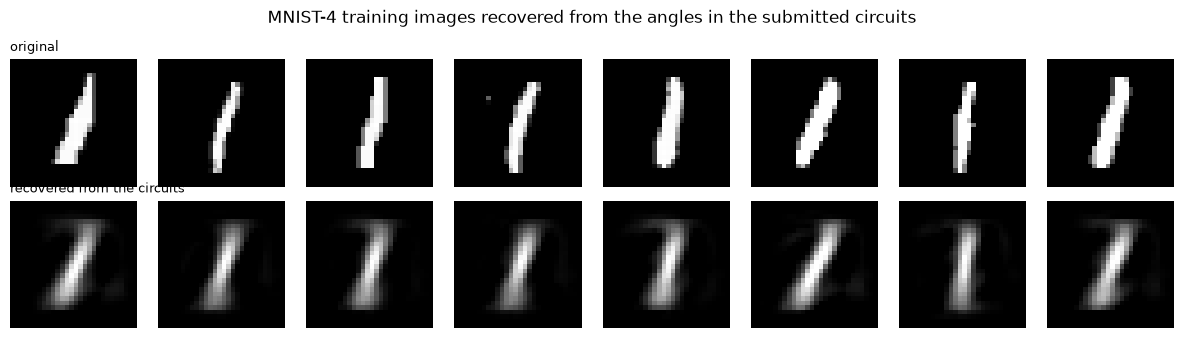

In [12]:
# --- step 3: undo the (assumed known) pre-processing -> pixels ---
def cloud_view(log, meas_qubits, epochs, y_true=None):
    """What the adversary builds from the log. Data points are recognised across epochs by identical angles.
    Returns unique points A (U, n), per-epoch implied labels votes (E, U) and, for scoring only, the true label of each unique point."""
    ang = np.round(log["ang"], 9)
    _, first, inv = np.unique(ang, axis=0, return_index=True, return_inverse=True)
    inv = np.asarray(inv).reshape(-1)
    U = len(first)
    votes = np.zeros((epochs, U), dtype=int)
    votes[log["epoch"], inv] = log["ev"][:, meas_qubits].argmax(1)       # class = qubit with the largest <Z>
    y_u = None
    if y_true is not None:
        y_u = np.zeros(U, dtype=int); y_u[inv] = y_true[log["idx"]]        # scoring only (not available to the adversary)
    return log["ang"][first], votes, y_u, first

A_rec, votes, y_u, first = cloud_view(lg, [0, 1, 2, 3], v_mnist["epochs"], sp["ytr"])
print(f"adversary identified {len(A_rec)} distinct training points from {len(lg['epoch'])} circuits (the victim has {len(sp['ytr'])})")

# map angles back to pixels with the victim's own transforms
def angles_to_pixels(A, sp):
    return sp["sc"].inverse_transform(sp["pca"].inverse_transform(sp["mm"].inverse_transform(A)))
pix_rec = np.clip(angles_to_pixels(A_rec, sp), 0, 255)
# the original training image that belongs to each recovered point (scoring only: use the stored first-occurrence index)
orig = sp["Xtr_raw"][lg["idx"][first]]
rmse = np.sqrt(np.mean((pix_rec - orig) ** 2, axis=1)) / 255
floor_recon = np.clip(sp["sc"].inverse_transform(sp["pca"].inverse_transform(sp["pca"].transform(sp["sc"].transform(orig)))), 0, 255)
floor = np.sqrt(np.mean((floor_recon - orig) ** 2, axis=1)) / 255
print(f"pixel RMSE (0-1 scale) of the recovered images versus the originals: {rmse.mean():.4f}")
print(f"... of the victim's own 8-component PCA reconstruction (the best any adversary could do): {floor.mean():.4f}")
fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
for j in range(8):
    ax[0, j].imshow(orig[j].reshape(28, 28), cmap="gray"); ax[1, j].imshow(pix_rec[j].reshape(28, 28), cmap="gray")
    ax[0, j].axis("off"); ax[1, j].axis("off")
ax[0, 0].set_title("original", fontsize=9, loc="left"); ax[1, 0].set_title("recovered from the circuits", fontsize=9, loc="left")
plt.suptitle("MNIST-4 training images recovered from the angles in the submitted circuits"); plt.tight_layout(); plt.show()

## 5. Label recovery: three voting heuristics

The cloud now has, for every training point, one implied label per epoch (the qubit with the largest Pauli-Z read-out). Early in
training these labels are mostly wrong, late in training mostly right, so the heuristics weight later epochs more:

* **Majority voting**: the most frequent label across epochs.
* **Linear weights**: epoch `e` counts with weight `e` (1, 2, 3, ...).
* **Exponential weights**: weight `2^e` up to the *rollover epoch* (the 90th-percentile epoch), constant afterwards, which mimics how
  accuracy rises quickly and then plateaus.

We also add a naive baseline of our own: **last epoch only**. The adversary's labels are *class indices*; the paper assumes
class `k` is read on qubit `k`, so the adversary's index is directly comparable with the true class index.

For every victim we report the accuracy of the recovered labels against the true labels (which only we know).

In [13]:
def label_votes(votes, n_cls, mode, rollover_pct=ROLLOVER_PCT):
    """votes: (E, U) implied labels per epoch. Returns (U,) labels."""
    E, U = votes.shape
    if mode == "majority":   w = np.ones(E)
    elif mode == "linear":   w = np.arange(1, E + 1, dtype=float)
    elif mode == "exponential":
        roll = int(np.ceil(np.percentile(np.arange(E), rollover_pct)))      # rollover epoch
        w = np.array([2.0 ** min(e, roll) for e in range(E)])
    elif mode == "last":     w = np.zeros(E); w[-1] = 1
    score = np.zeros((U, n_cls))
    for e in range(E): np.add.at(score, (np.arange(U), votes[e]), w[e])
    return score.argmax(1)

MODES = ["majority", "linear", "exponential"]
def heuristic_accuracies(votes, y_u, n_cls):
    return {m: float((label_votes(votes, n_cls, m) == y_u).mean()) for m in MODES + ["last"]}

def matched_acc(labels, y, n_lab, n_cls):
    """Permutation-invariant accuracy: best one-to-one matching of adversary labels to true classes."""
    cm = np.zeros((n_lab, n_cls)); np.add.at(cm, (labels, y), 1)
    r_, c_ = linear_sum_assignment(-cm)
    return cm[r_, c_].sum() / len(y)

ATTACK = {}      # (ds, seed, regime) -> dict(A, votes, y_u, ...)
def attack_view(v, meas=None):
    sp = v["split"]; C = sp["n_classes"]
    meas = list(range(C)) if meas is None else meas
    A, votes, y_u, first = cloud_view(v["log"], meas, v["epochs"], sp["ytr"])
    return dict(A=A, votes=votes, y_u=y_u, C=C)

rows, t0 = [], time.time()
for ds in ["iris"] + BIG_DATASETS:
    seeds = SEEDS_IRIS if ds == "iris" else SEEDS_BIG
    for sd in seeds:
        v = run_victim(ds, sd, "clean")
        av = attack_view(v); ATTACK[(ds, sd, "clean")] = av
        acc = heuristic_accuracies(av["votes"], av["y_u"], av["C"])
        rows.append(dict(dataset=SPEC[ds]["title"], seed=sd, victim_train_acc=v["hist"]["train_acc"][-1], victim_test_acc=v["hist"]["test_acc"][-1],
                         **{f"acc_{m}": a for m, a in acc.items()}))
    print(f"{ds} done ({time.time()-t0:.0f} s)", flush=True)
FIG2 = pd.DataFrame(rows)
FIG2_MEAN = FIG2.groupby("dataset", sort=False).mean(numeric_only=True).drop(columns="seed")
display((FIG2_MEAN * 100).round(1))
means = FIG2_MEAN[[f"acc_{m}" for m in MODES]].mean() * 100
print("mean over the %d datasets run: majority %.1f %%, linear %.1f %%, exponential %.1f %%   (paper, five datasets: 86 / 90 / 92)" % ((len(FIG2_MEAN),) + tuple(means)))

iris done (9 s)


mnist done (9 s)


fashion done (112 s)


kuzu done (228 s)


letters done (309 s)


,victim_train_acc,victim_test_acc,acc_majority,acc_linear,acc_exponential,acc_last
dataset,,,,,,
Iris,91.5,85.0,86.2,88.5,92.2,91.5
MNIST-4,86.3,90.7,87.3,87.4,87.6,86.3
Fashion-4,89.3,89.3,88.9,88.7,89.1,89.3
Kuzushiji-4,77.6,80.3,78.0,77.9,78.0,77.6
Letters-4,87.6,88.3,89.6,89.1,88.4,87.5


mean over the 5 datasets run: majority 86.0 %, linear 86.3 %, exponential 87.1 %   (paper, five datasets: 86 / 90 / 92)


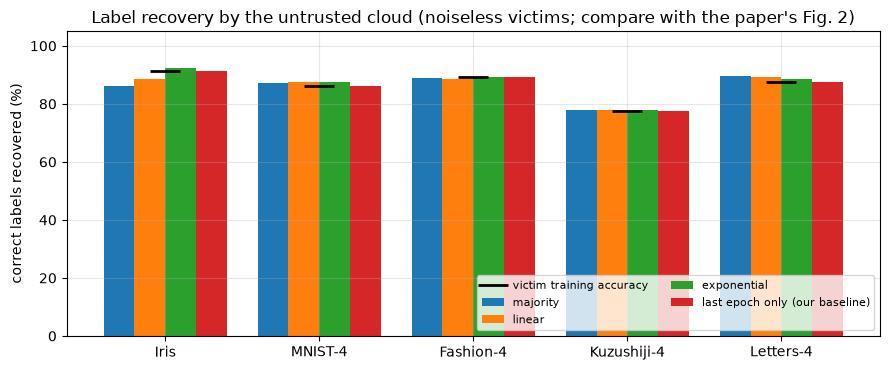

In [14]:
# --- Fig. 2 redrawn: label-recovery accuracy per dataset and heuristic ---
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(FIG2_MEAN)); wdt = 0.2
for j, m in enumerate(MODES + ["last"]):
    ax.bar(x + (j - 1.5) * wdt, FIG2_MEAN[f"acc_{m}"] * 100, wdt, label={"last": "last epoch only (our baseline)"}.get(m, m))
ax.plot(x, FIG2_MEAN["victim_train_acc"] * 100, "k_", markersize=22, mew=2, label="victim training accuracy")
ax.set_xticks(x); ax.set_xticklabels(FIG2_MEAN.index); ax.set_ylabel("correct labels recovered (%)"); ax.set_ylim(0, 105)
ax.set_title("Label recovery by the untrusted cloud (noiseless victims; compare with the paper's Fig. 2)"); ax.legend(fontsize=8, ncol=2, loc="lower right")
plt.tight_layout(); plt.show()

## 6. How good must the victim be? (noisy Iris, label recovery versus training accuracy)

The attack can only be as good as the victim's own model: if the QNN is wrong on a point in every epoch, no voting rule can recover
that label. The paper shows this in its Fig. 3 for the noisy 4-qubit Iris model: label-recovery accuracy rises with the victim's
final training accuracy, and exponential weights are best. We reproduce the experiment with many short noisy training runs of
different lengths and noise strengths, which yield victims with final training accuracies from about 40 % to over 90 %.

The noise is the Hanoi-calibrated model scaled by a factor (1 = Hanoi); `SWEEP_EPOCHS` and `SWEEP_NOISE` in the configuration cell set the grid.

noise x1.0 done (227 s)


noise x4.0 done (392 s)


noise x10.0 done (580 s)


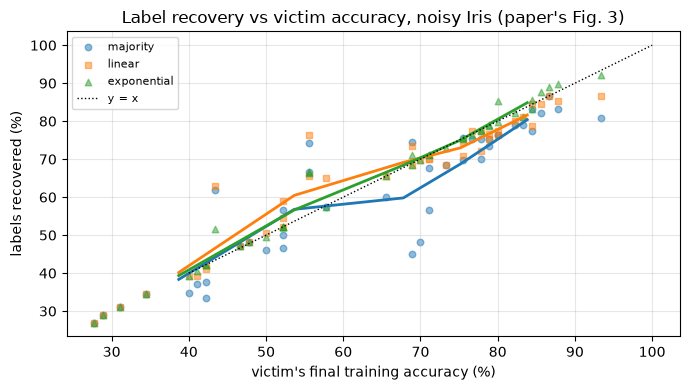

42 runs, victim final training accuracy from 28 % to 93 % (mean 64 %)
average label recovery over the sweep: majority 60.9 %, linear 64.2 %, exponential 64.6 %   (paper, averaged over its accuracy range: 70 / 76 / 80)
restricted to victims with >= 80 % training accuracy (10 runs): majority 80.4, linear 82.1, exponential 85.6


In [15]:
rows, t0 = [], time.time()
for nm in SWEEP_NOISE:
    for ep in SWEEP_EPOCHS:
        for sd in SWEEP_SEEDS:
            v = run_victim("iris", sd, "noisy", epochs=ep, noise_mult=nm)
            av = attack_view(v)
            acc = heuristic_accuracies(av["votes"], av["y_u"], av["C"])
            rows.append(dict(noise_x=nm, epochs=ep, seed=sd, train_acc=v["hist"]["train_acc"][-1], **{f"acc_{m}": a for m, a in acc.items()}))
    print(f"noise x{nm} done ({time.time()-t0:.0f} s)", flush=True)
SWEEP = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4))
for m, mk in zip(MODES, ["o", "s", "^"]):
    ax.scatter(SWEEP["train_acc"] * 100, SWEEP[f"acc_{m}"] * 100, s=22, marker=mk, alpha=0.5, label=m)
bins = np.array([0, 50, 60, 70, 80, 90, 101]); centre = []
for lo, hi in zip(bins[:-1], bins[1:]):
    sel = (SWEEP["train_acc"] * 100 >= lo) & (SWEEP["train_acc"] * 100 < hi)
    if sel.sum() >= 2: centre.append((SWEEP.loc[sel, "train_acc"].mean() * 100, *[SWEEP.loc[sel, f"acc_{m}"].mean() * 100 for m in MODES]))
centre = np.array(centre)
if len(centre):
    for j, m in enumerate(MODES): ax.plot(centre[:, 0], centre[:, 1 + j], "-", lw=2)
ax.plot([40, 100], [40, 100], "k:", lw=1, label="y = x")
ax.set_xlabel("victim's final training accuracy (%)"); ax.set_ylabel("labels recovered (%)")
ax.set_title("Label recovery vs victim accuracy, noisy Iris (paper's Fig. 3)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
FIG3_MEAN = SWEEP[[f"acc_{m}" for m in MODES]].mean() * 100
print(f"{len(SWEEP)} runs, victim final training accuracy from {SWEEP.train_acc.min()*100:.0f} % to {SWEEP.train_acc.max()*100:.0f} % (mean {SWEEP.train_acc.mean()*100:.0f} %)")
print("average label recovery over the sweep: majority %.1f %%, linear %.1f %%, exponential %.1f %%   (paper, averaged over its accuracy range: 70 / 76 / 80)" % tuple(FIG3_MEAN))
hi_sel = SWEEP["train_acc"] >= 0.8
print("restricted to victims with >= 80 %% training accuracy (%d runs): majority %.1f, linear %.1f, exponential %.1f" % ((hi_sel.sum(),) + tuple(SWEEP.loc[hi_sel, [f"acc_{m}" for m in MODES]].mean() * 100)))

## 7. Refining the stolen labels: iterative k-fold cross-validation

Voting leaves some wrong labels (the points the victim's QNN misclassifies in most epochs). The adversary now treats the stolen
inputs and labels as a *noisy-label dataset* and cleans it with classical machine learning:

1. For each classifier of an ensemble (RandomForest, LogisticRegression, SVC, MLP) and each `k` in (5, 7, 10, 15), predict every point's class probabilities from a
   model that did **not** see that point (cross-validated predictions), then average over `k`.
2. A point is **suspect** if *all four* classifiers' predicted class differs from its current label.
3. For a suspect point take the ensemble-mean class probabilities; if the most probable class has probability at least 0.8 the label is **updated**,
   otherwise the point is **pruned** (dropped).
4. Repeat on the cleaned set (here at most 3 rounds, stopping when nothing changes).

We start from the exponential-weights labels, as in the paper, and measure (a) the reduction in the *number* of wrong labels and (b) the
fraction of points pruned. These are evaluated against the true labels, which only we know.

In [16]:
def make_clf(name, seed):
    return {"RF":  RandomForestClassifier(n_estimators=60, random_state=seed, n_jobs=1),
            "LR":  LogisticRegression(max_iter=2000),
            "SVC": SVC(probability=True, random_state=seed),
            "MLP": MLPClassifier(hidden_layer_sizes=(32,), solver="lbfgs", max_iter=300, random_state=seed)}[name]   # CHOICE: lbfgs for speed on small data
CLF_NAMES = ["RF", "LR", "SVC", "MLP"]

def refine_labels(A, labels, seed=SEED, ks=KFOLDS, thr=CONF_THR, rounds=REFINE_ROUNDS):
    """Paper's k-fold refinement. Returns (refined labels, keep mask)."""
    N = len(A); keep = np.ones(N, bool); lab = labels.copy()
    for rd in range(rounds):
        idx = np.where(keep)[0]; Ak, lk = A[idx], lab[idx]
        cls = np.unique(lk); cnt = np.array([(lk == c).sum() for c in cls])
        ks_ok = [k for k in ks if cnt.min() >= k]
        if not ks_ok or len(cls) < 2: break
        P = {nm: np.zeros((len(idx), len(cls))) for nm in CLF_NAMES}
        for nm in CLF_NAMES:
            for k in ks_ok:
                pr = cross_val_predict(make_clf(nm, seed), Ak, lk, cv=StratifiedKFold(k, shuffle=True, random_state=seed), method="predict_proba", n_jobs=2)
                P[nm] += pr / len(ks_ok)
        suspect = np.all([cls[P[nm].argmax(1)] != lk for nm in CLF_NAMES], axis=0)     # all classifiers disagree with the label
        Pm = np.mean([P[nm] for nm in CLF_NAMES], axis=0)
        newlab, conf = cls[Pm.argmax(1)], Pm.max(1)
        upd, prune = suspect & (conf >= thr), suspect & (conf < thr)
        lab[idx[upd]] = newlab[upd]; keep[idx[prune]] = False
        if not (upd.any() or prune.any()): break
    return lab, keep

REFINED = {}
def refine_run(key, av):
    lab0 = label_votes(av["votes"], av["C"], "exponential")
    lab1, keep = refine_labels(av["A"], lab0)
    w0, w1 = int((lab0 != av["y_u"]).sum()), int((lab1[keep] != av["y_u"][keep]).sum())
    REFINED[key] = dict(A=av["A"][keep], y=lab1[keep], keep=keep, y_true=av["y_u"][keep])
    return dict(wrong_before=w0, wrong_after=w1, wrong_reduction_pct=100 * (1 - w1 / w0) if w0 else np.nan,
                pruned_pct=100 * (1 - keep.mean()), label_acc_before=1 - w0 / len(keep), label_acc_after=1 - w1 / keep.sum())

# victims for Fig. 4: the five clean victims of Section 5 plus noisy Iris victims (the paper's Fig. 4 uses noisy victims at about 90 % accuracy)
for sd in SEEDS_IRIS:
    v = run_victim("iris", sd, "noisy"); ATTACK[("iris", sd, "noisy")] = attack_view(v)
rows, t0 = [], time.time()
for key, av in list(ATTACK.items()):
    ds, sd, regime = key
    if regime == "noisy" and key[1] not in SEEDS_IRIS: continue
    v = VICT[(ds, sd, regime, None, 1.0)]
    r_ = refine_run(key, av)
    rows.append(dict(dataset=SPEC[ds]["title"] + (" (noisy)" if regime == "noisy" else ""), seed=sd, victim_train_acc=v["hist"]["train_acc"][-1], **r_))
    print(f"refined {rows[-1]['dataset']} seed {sd}  ({time.time()-t0:.0f} s)", flush=True)
FIG4 = pd.DataFrame(rows)
FIG4_MEAN = FIG4.groupby("dataset", sort=False).mean(numeric_only=True).drop(columns="seed")
display(FIG4_MEAN.round(3))

refined Iris seed 42  (20 s)


refined Iris seed 43  (38 s)


refined Iris seed 44  (43 s)


refined MNIST-4 seed 42  (101 s)


refined Fashion-4 seed 42  (142 s)


...

refined Letters-4 seed 42  (248 s)


refined Iris (noisy) seed 42  (268 s)


refined Iris (noisy) seed 43  (283 s)


refined Iris (noisy) seed 44  (291 s)


,victim_train_acc,wrong_before,wrong_after,wrong_reduction_pct,pruned_pct,label_acc_before,label_acc_after
dataset,,,,,,,
Iris,0.915,7.000,6.667,4.167,0.741,0.922,0.925
MNIST-4,0.863,87.000,82.000,5.747,1.143,0.876,0.882
Fashion-4,0.893,76.000,69.000,9.211,0.714,0.891,0.901
Kuzushiji-4,0.776,154.000,148.000,3.896,2.714,0.780,0.783
Letters-4,0.876,80.000,72.000,10.000,1.449,0.884,0.894
Iris (noisy),0.896,8.667,7.667,11.429,1.115,0.903,0.914


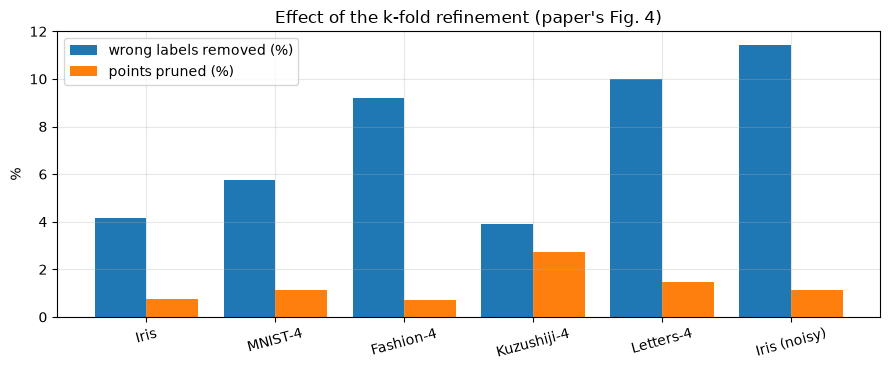

mean over the 5 victims (8-qubit sets + noisy Iris): wrong labels reduced by 8.1 %, points pruned 1.4 %   (paper, five victims: about 30 % and 2 %)
overall label accuracy of the stolen datasets: before refinement 86.7 %, after 87.5 %


In [17]:
# --- Fig. 4 redrawn ---
fig, ax = plt.subplots(figsize=(9, 3.8)); x = np.arange(len(FIG4_MEAN))
ax.bar(x - 0.2, FIG4_MEAN["wrong_reduction_pct"], 0.4, label="wrong labels removed (%)")
ax.bar(x + 0.2, FIG4_MEAN["pruned_pct"], 0.4, label="points pruned (%)")
ax.set_xticks(x); ax.set_xticklabels(FIG4_MEAN.index, rotation=15); ax.set_ylabel("%"); ax.legend()
ax.set_title("Effect of the k-fold refinement (paper's Fig. 4)"); plt.tight_layout(); plt.show()
main = FIG4_MEAN.loc[[SPEC[d]["title"] for d in BIG_DATASETS] + ["Iris (noisy)"]]
print("mean over the %d victims (8-qubit sets + noisy Iris): wrong labels reduced by %.1f %%, points pruned %.1f %%   (paper, five victims: about 30 %% and 2 %%)" % (len(main), main.wrong_reduction_pct.mean(), main.pruned_pct.mean()))
print("overall label accuracy of the stolen datasets: before refinement %.1f %%, after %.1f %%" % (100 * main.label_acc_before.mean(), 100 * main.label_acc_after.mean()))

## 8. Reusing the stolen data: clone model versus the victim's model

The goal of the theft is *reuse*: train a model of one's own on the stolen, relabelled data, or sell the data. We test this as the
paper does (Fig. 5): a fresh 4-qubit QNN is trained on the noisy Iris backend for 15 epochs, once on the victim's original training set and once on
the adversary's stolen-and-refined set (fewer points and a few wrong labels). Both models are scored on the **same original test set with true labels**.

The classical rows of the table answer an obvious question the paper does not ask: how much of the value of the stolen set is already
available to a plain `RandomForest` or RBF `SVC` trained on the same 4 or 8 numbers per point? (Those models also run for the four 8-qubit
sets. A quantum clone of the 8-qubit sets is trained only in the full-size run, `EPOCHS_CLONE_BIG > 0`.)

In [18]:
CLONE_ROWS, CLONE_CURVES, t0 = [], {"orig": [], "stolen": []}, time.time()
def classical_scores(A_tr, y_tr, A_te, y_te, seed):
    out = {}
    for nm, clf in [("RF", RandomForestClassifier(n_estimators=200, random_state=seed)), ("SVC_rbf", SVC(kernel="rbf", random_state=seed))]:
        out[nm] = float(clf.fit(A_tr, y_tr).score(A_te, y_te))
    return out

# (a) quantum clones on noisy Iris (the paper's Fig. 5)
for sd in SEEDS_IRIS:
    sp = SPLITS[("iris", sd)]; R_ = REFINED[("iris", sd, "noisy")]; sim = get_sim("iris", 1.0)
    res = {}
    for tag, (A_, y_) in {"orig": (sp["Atr"], sp["ytr"]), "stolen": (R_["A"], R_["y"])}.items():
        W, log, h = train_qnn(sim, A_, y_, sp["Ate"], sp["yte"], 3, EPOCHS_CLONE_IRIS, LR, BATCH["iris"], seed=sd + 100)
        res[tag] = h; CLONE_CURVES[tag].append((h["train_acc"], h["test_acc"]))
        CLONE_ROWS.append(dict(dataset="Iris (noisy)", model="QNN", data=tag, seed=sd, n_train=len(y_), train_acc=h["train_acc"][-1], test_acc=h["test_acc"][-1]))
    print(f"iris seed {sd}: clone trained ({time.time()-t0:.0f} s)", flush=True)

# (b) classical clones (all datasets) and optional quantum clones of the 8-qubit sets
for key, R_ in REFINED.items():
    ds, sd, regime = key
    if regime == "noisy": continue
    sp = SPLITS[(ds, sd)]
    for tag, (A_, y_) in {"orig": (sp["Atr"], sp["ytr"]), "stolen": (R_["A"], R_["y"])}.items():
        for nm, a in classical_scores(A_, y_, sp["Ate"], sp["yte"], sd).items():
            CLONE_ROWS.append(dict(dataset=SPEC[ds]["title"], model=nm, data=tag, seed=sd, n_train=len(y_), train_acc=np.nan, test_acc=a))
    if ds in BIG_DATASETS and EPOCHS_CLONE_BIG > 0:
        for tag, (A_, y_) in {"orig": (sp["Atr"], sp["ytr"]), "stolen": (R_["A"], R_["y"])}.items():
            W, log, h = train_qnn(get_sim(ds), A_, y_, sp["Ate"], sp["yte"], sp["n_classes"], EPOCHS_CLONE_BIG, LR, BATCH[ds], seed=sd + 100)
            CLONE_ROWS.append(dict(dataset=SPEC[ds]["title"], model="QNN", data=tag, seed=sd, n_train=len(y_), train_acc=h["train_acc"][-1], test_acc=h["test_acc"][-1]))
        print(f"{ds}: quantum clones trained ({time.time()-t0:.0f} s)", flush=True)
CLONE = pd.DataFrame(CLONE_ROWS)
tab = CLONE.groupby(["dataset", "model", "data"], sort=False)[["n_train", "train_acc", "test_acc"]].mean()
tab["test_acc_std"] = CLONE.groupby(["dataset", "model", "data"], sort=False)["test_acc"].std()
display((tab * [1, 100, 100, 100]).round(1))

iris seed 42: clone trained (88 s)


iris seed 43: clone trained (159 s)


iris seed 44: clone trained (214 s)


mnist: quantum clones trained (317 s)


fashion: quantum clones trained (385 s)


kuzu: quantum clones trained (473 s)


letters: quantum clones trained (558 s)


n_train  train_acc  test_acc  test_acc_std
dataset      model   data                                              
Iris (noisy) QNN     orig       90.0       89.6      81.1           5.4
                     stolen     88.7       91.0      79.4           5.1
Iris         RF      orig       90.0        NaN      96.7           1.7
             SVC_rbf orig       90.0        NaN      95.6           1.9
             RF      stolen     89.0        NaN      90.6           2.5
             SVC_rbf stolen     89.0        NaN      87.2           1.9
MNIST-4      RF      orig      700.0        NaN      97.7           NaN
             SVC_rbf orig      700.0        NaN      96.0           NaN
             RF      stolen    692.0        NaN      89.0           NaN
             SVC_rbf stolen    692.0        NaN      88.7           NaN
             QNN     orig      700.0       87.7      89.3           NaN
                     stolen    692.0       84.5      78.3           NaN
Fashion-4    RF      orig      700.0        NaN      92.7           NaN
             SVC_rbf orig      700.0        NaN      92.3           NaN
             RF      stolen    695.0        NaN      88.3           NaN
             SVC_rbf stolen    695.0        NaN      89.7           NaN
             QNN     orig      700.0       87.0      87.3           NaN
                     stolen    695.0       94.4      83.0           NaN
Kuzushiji-4  RF      orig      700.0        NaN      93.3           NaN
             SVC_rbf orig      700.0        NaN      94.7           NaN
             RF      stolen    681.0        NaN      77.3           NaN
             SVC_rbf stolen    681.0        NaN      79.0           NaN
             QNN     orig      700.0       77.7      77.0           NaN
                     stolen    681.0       83.4      66.7           NaN
Letters-4    RF      orig      700.0        NaN      93.7           NaN
             SVC_rbf orig      700.0        NaN      95.3           NaN
             RF      stolen    680.0        NaN      88.3           NaN
             SVC_rbf stolen    680.0        NaN      90.3           NaN
             QNN     orig      700.0       89.0      87.0           NaN
                     stolen    680.0       96.2      87.3           NaN

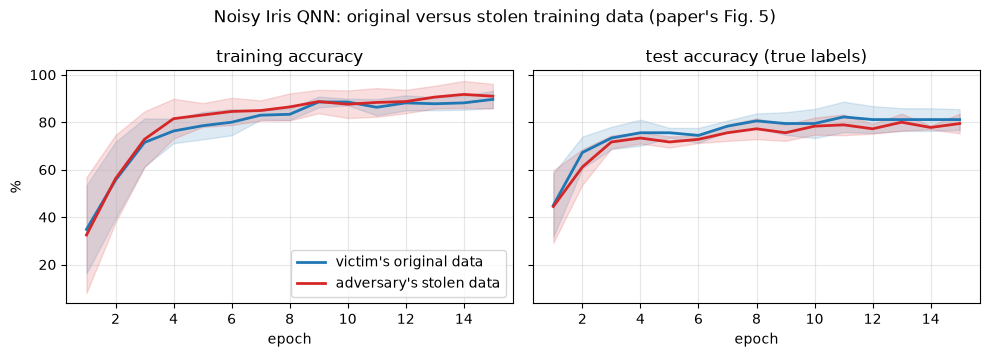

train_acc      test_acc     
            mean  std     mean  std
data                               
orig        89.6  4.5     81.1  5.4
stolen      91.0  6.3     79.4  5.1

In [19]:
# --- Fig. 5 redrawn: noisy Iris, QNN trained on the victim's data versus on the stolen data ---
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for tag, col in [("orig", "tab:blue"), ("stolen", "tab:red")]:
    tr = np.array([c[0] for c in CLONE_CURVES[tag]]) * 100; te = np.array([c[1] for c in CLONE_CURVES[tag]]) * 100
    for a, arr, ttl in [(ax[0], tr, "training accuracy"), (ax[1], te, "test accuracy (true labels)")]:
        ep_ = np.arange(1, arr.shape[1] + 1)
        a.plot(ep_, arr.mean(0), color=col, lw=2, label={"orig": "victim's original data", "stolen": "adversary's stolen data"}[tag])
        a.fill_between(ep_, arr.mean(0) - arr.std(0), arr.mean(0) + arr.std(0), color=col, alpha=0.15); a.set_title(ttl); a.set_xlabel("epoch")
ax[0].set_ylabel("%"); ax[0].legend(); plt.suptitle("Noisy Iris QNN: original versus stolen training data (paper's Fig. 5)"); plt.tight_layout(); plt.show()
q = CLONE[(CLONE.model == "QNN") & (CLONE.dataset == "Iris (noisy)")].groupby("data")[["train_acc", "test_acc"]].agg(["mean", "std"]) * 100
display(q.round(1))

## 9. The defence: a masking class and a modified loss

The adversary's label inference rests on one assumption: the class of a point is the qubit with the largest Pauli-Z read-out, and the user reads
exactly the first `C` qubits. The paper's defence breaks that assumption in two ways.

* **Masking class.** Train with `C + 1` classes (one extra, "mask" class) and have the circuit read out all `C + 1` qubits. The user's real
  classes live on a **secret subset `S` of `C` qubits**; the remaining qubit is the mask. An adversary who reads all `C + 1` qubits does not know
  how many classes there are or which qubits matter.
* **Modified cost** `L_total = L_correct + alpha * L_adversary`. `L_correct` is the usual cross-entropy on the read-outs of `S` with the true labels;
  `L_adversary` is a cross-entropy on the read-outs of **all** measured qubits against deliberately *wrong* labels (here a fixed random wrong qubit
  per training point, never the point's own class qubit). The network can satisfy both losses only by making the true class win among the qubits of `S`
  while a *different* qubit wins when all qubits are compared.

We score the adversary's exponential-weights labels two ways: **strict** (the adversary's class index must equal the true class index) and
**matched** (best one-to-one matching of its labels to the true classes, which grants it the ability to cluster even without knowing class names). As a sanity check we
also score an **informed** adversary who learned the secret qubits `S`: the defence is only as good as the secrecy of `S`.

For the model quality we compare the *user's own* training accuracy (read on `S`) with the undefended model's training accuracy, with the same seed, epochs and noise setting
(Iris: noisy backend as in the paper, the others noiseless).

In [20]:
def run_defence(ds, seed, alpha, regime):
    if (ds, seed) not in SPLITS: SPLITS[(ds, seed)] = make_split(ds, seed)
    sp = SPLITS[(ds, seed)]; C_ = sp["n_classes"]; M = list(range(C_ + 1))
    r = np.random.default_rng(10_000 + seed)
    S = sorted(r.choice(C_ + 1, C_, replace=False).tolist())              # the user's secret qubits (the one left over is the masking class)
    y_adv = np.array([r.choice([q for q in M if q != S[c]]) for c in sp["ytr"]])      # CHOICE: fixed random wrong qubit per training point
    ep = epochs_for(ds)
    sim = get_sim(ds, 1.0 if regime == "noisy" else 0.0)
    W, log, h = train_qnn(sim, sp["Atr"], sp["ytr"], sp["Ate"], sp["yte"], C_, ep, LR, BATCH[ds], seed, meas_qubits=S, adv=dict(alpha=alpha, qubits=M, y_adv=y_adv))
    A_, votes_, y_u_, _ = cloud_view(log, M, ep, sp["ytr"])                 # adversary reads ALL C+1 measured qubits
    lab = label_votes(votes_, C_ + 1, "exponential")
    _, votes_s, y_s, _ = cloud_view(log, S, ep, sp["ytr"])                  # informed adversary (knows S)
    ref = VICT[(ds, seed, regime, None, 1.0)]
    nodef_lab = label_votes(ATTACK[(ds, seed, regime)]["votes"], C_, "exponential")
    return dict(dataset=SPEC[ds]["title"], seed=seed, alpha=alpha, secret_qubits=str(S),
                nodefence_label_acc=float((nodef_lab == ATTACK[(ds, seed, regime)]["y_u"]).mean()),
                defended_strict=float((lab == y_u_).mean()), defended_matched=matched_acc(lab, y_u_, C_ + 1, C_),
                informed_adversary=float((label_votes(votes_s, C_, "exponential") == y_s).mean()),
                user_train_acc_nodefence=ref["hist"]["train_acc"][-1], user_train_acc_defended=h["train_acc"][-1],
                user_test_acc_nodefence=ref["hist"]["test_acc"][-1], user_test_acc_defended=h["test_acc"][-1])

rows, t0 = [], time.time()
for ds in ["iris"] + BIG_DATASETS:
    seeds = SEEDS_IRIS if ds == "iris" else SEEDS_BIG
    regime = "noisy" if ds == "iris" else "clean"
    for sd in seeds:
        for al in (ALPHAS if ds == "iris" else [ALPHA_DEFENCE]):
            rows.append(run_defence(ds, sd, al, regime))
    print(f"{ds} defended ({time.time()-t0:.0f} s)", flush=True)
DEF = pd.DataFrame(rows)
DEF_MAIN = DEF[DEF.alpha == ALPHA_DEFENCE].groupby("dataset", sort=False).mean(numeric_only=True).drop(columns=["seed", "alpha"])
display((DEF_MAIN * 100).round(1))
if len(ALPHAS) > 1:
    print("effect of alpha on noisy Iris (mean over seeds, %):")
    display((DEF[DEF.dataset == "Iris"].groupby("alpha").mean(numeric_only=True)[["defended_strict", "defended_matched", "user_train_acc_defended"]] * 100).round(1))

iris defended (472 s)


mnist defended (571 s)


fashion defended (671 s)


kuzu defended (772 s)


letters defended (862 s)


,nodefence_label_acc,defended_strict,defended_matched,informed_adversary,user_train_acc_nodefence,user_train_acc_defended,user_test_acc_nodefence,user_test_acc_defended
dataset,,,,,,,,
Iris,90.3,44.5,69.9,87.4,89.6,86.7,86.1,81.7
MNIST-4,87.6,6.0,75.3,88.4,86.3,88.1,90.7,89.3
Fashion-4,89.1,1.0,80.4,88.0,89.3,87.7,89.3,88.0
Kuzushiji-4,78.0,10.4,67.3,79.7,77.6,80.7,80.3,78.0
Letters-4,88.4,3.5,72.6,89.4,87.6,89.1,88.3,86.0


effect of alpha on noisy Iris (mean over seeds, %):


,defended_strict,defended_matched,user_train_acc_defended
alpha,,,
0.0,33.7,79.9,88.9
1.0,44.5,69.9,86.7
3.0,28.3,51.3,15.6


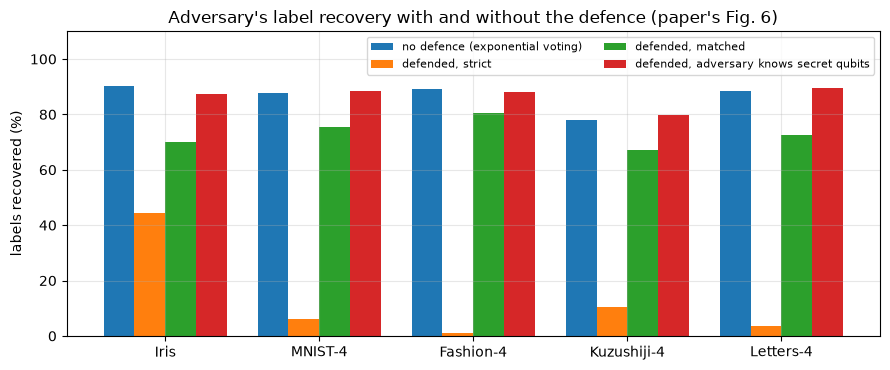

mean drop of the adversary's strict label accuracy: 73.6 points (paper: about 70)
mean change of the user's training accuracy: +0.4 points (paper: about -2)


In [21]:
# --- Fig. 6 redrawn ---
fig, ax = plt.subplots(figsize=(9, 3.8)); x = np.arange(len(DEF_MAIN)); w_ = 0.2
ax.bar(x - 1.5 * w_, DEF_MAIN["nodefence_label_acc"] * 100, w_, label="no defence (exponential voting)")
ax.bar(x - 0.5 * w_, DEF_MAIN["defended_strict"] * 100, w_, label="defended, strict")
ax.bar(x + 0.5 * w_, DEF_MAIN["defended_matched"] * 100, w_, label="defended, matched")
ax.bar(x + 1.5 * w_, DEF_MAIN["informed_adversary"] * 100, w_, label="defended, adversary knows secret qubits")
ax.set_xticks(x); ax.set_xticklabels(DEF_MAIN.index); ax.set_ylabel("labels recovered (%)"); ax.set_ylim(0, 110); ax.legend(fontsize=8, ncol=2, loc="upper right")
ax.set_title("Adversary's label recovery with and without the defence (paper's Fig. 6)"); plt.tight_layout(); plt.show()
drop_pts = (DEF_MAIN["nodefence_label_acc"] - DEF_MAIN["defended_strict"]).mean() * 100
print("mean drop of the adversary's strict label accuracy: %.1f points (paper: about 70)" % drop_pts)
print("mean change of the user's training accuracy: %+.1f points (paper: about -2)" % (100 * (DEF_MAIN["user_train_acc_defended"] - DEF_MAIN["user_train_acc_nodefence"]).mean()))

## 10. Side by side with the paper

For every claim of the paper that the notebook can test, the table shows the paper's value, our value and a verdict. The rule: the claim is
**reproduced** when our value is within 2 percentage points of the paper's; otherwise **exceeded** or **not reached** with the gap (in the direction that
is better for the attacker, except for the defence rows where lower adversary accuracy is better for the defender). The paper's figures are plots, so we only compare numbers it states in text; per-dataset values are
read from the sentences of Sections 5.2.3 and 5.2.5.

In [22]:
def verdict(paper, ours, tol=2.0, lower_better=False):
    if np.isnan(paper): return "extra measure (no paper value)"
    gap = ours - paper
    if np.isnan(ours): return "cannot be checked"
    if abs(gap) <= tol: return "reproduced"
    better = gap < 0 if lower_better else gap > 0
    return ("exceeded" if better else "not reached") + f" ({gap:+.1f})"

rows = []
def add(claim, paper, ours, **kw):
    rows.append(dict(claim=claim, paper=paper, notebook=round(float(ours), 1) if ours == ours else np.nan, verdict=verdict(paper, ours, **kw)))

# C1 / C2
for m, p1_ in zip(MODES, [86, 90, 92]):
    add(f"C1 mean label recovery, noiseless victims, {m} (%)", p1_, means[f"acc_{m}"])
for m, p2_ in zip(MODES, [70, 76, 80]):
    add(f"C2 mean label recovery over noisy-Iris sweep, {m} (%)", p2_, FIG3_MEAN[f"acc_{m}"])
# C3 / C4
paper_red = {"Fashion-4": 18, "Kuzushiji-4": 22, "Letters-4": 35, "MNIST-4": 70, "Iris (noisy)": 20}
paper_prn = {"Fashion-4": 1.5, "Kuzushiji-4": 2, "Letters-4": 3.5, "MNIST-4": 1.5, "Iris (noisy)": 2}
for k_ in paper_red:
    if k_ in FIG4_MEAN.index: add(f"C3 wrong labels removed by refinement, {k_} (%)", paper_red[k_], FIG4_MEAN.loc[k_, "wrong_reduction_pct"])
add("C3 mean wrong labels removed (%, datasets run)", 30, main.wrong_reduction_pct.mean())
for k_ in paper_prn:
    if k_ in FIG4_MEAN.index: add(f"C4 points pruned, {k_} (%)", paper_prn[k_], FIG4_MEAN.loc[k_, "pruned_pct"], lower_better=True)
add("C4 mean points pruned (%)", 2, main.pruned_pct.mean(), lower_better=True)
# C5
qq = CLONE[(CLONE.model == "QNN") & (CLONE.dataset == "Iris (noisy)")].groupby("data")[["train_acc", "test_acc"]].mean() * 100
add("C5 clone on victim's Iris data, training accuracy (%)", 93, qq.loc["orig", "train_acc"])
add("C5 clone on victim's Iris data, test accuracy (%)", 88, qq.loc["orig", "test_acc"])
add("C5 clone on stolen Iris data, training accuracy (%)", 90, qq.loc["stolen", "train_acc"])
add("C5 clone on stolen Iris data, test accuracy (%)", 86, qq.loc["stolen", "test_acc"])
add("C5 test-accuracy gap victim data minus stolen data (points)", 2, qq.loc["orig", "test_acc"] - qq.loc["stolen", "test_acc"], lower_better=True)
# C6
add("C6 about 90 % of labels extracted (mean exponential voting, 5 datasets, %)", 90, means["acc_exponential"])
add("C6 about 90 % of labels extracted after refinement (%)", 90, 100 * main.label_acc_after.mean())
# C7 / C8
paper_nodef = {"Fashion-4": 100, "Kuzushiji-4": 100, "Letters-4": 100, "MNIST-4": 90, "Iris": 100}
paper_def = {"Fashion-4": 20, "Kuzushiji-4": 40, "Letters-4": 30, "MNIST-4": 10, "Iris": 25}
for k_ in paper_nodef:
    if k_ in DEF_MAIN.index: add(f"C7 no defence, exponential voting, {k_} (%)", paper_nodef[k_], DEF_MAIN.loc[k_, "nodefence_label_acc"] * 100)
for k_ in paper_def:
    if k_ in DEF_MAIN.index: add(f"C8 defended adversary accuracy (strict), {k_} (%)", paper_def[k_], DEF_MAIN.loc[k_, "defended_strict"] * 100, lower_better=True)
paper_def_mean = np.mean([paper_def[k_] for k_ in paper_def if k_ in DEF_MAIN.index])
add("C8 mean defended adversary accuracy (strict, %, datasets run; paper value = mean over the same datasets)", paper_def_mean, DEF_MAIN["defended_strict"].mean() * 100, lower_better=True)
add("C8 mean reduction of adversary accuracy (points, strict)", 70, drop_pts)
add("C8x mean defended adversary accuracy (matched = clustering adversary; not in the paper, %)", np.nan, DEF_MAIN["defended_matched"].mean() * 100)
add("C8x mean defended accuracy of an adversary who knows the secret qubits (not in the paper, %)", np.nan, DEF_MAIN["informed_adversary"].mean() * 100)
# C9
add("C9 user's training accuracy change under the defence (points)", -2, 100 * (DEF_MAIN["user_train_acc_defended"] - DEF_MAIN["user_train_acc_nodefence"]).mean())
# C10
add("C10 max error of the data angles extracted from the circuits (radians; paper: 'easy to extract')", 0, ANGLE_ERR, tol=1e-6, lower_better=True)
COMPARE = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 90); pd.set_option("display.max_rows", 100)
display(COMPARE)
print(COMPARE.verdict.str.split(" ").str[0].value_counts().to_string())

,claim,paper,notebook,verdict
0,"C1 mean label recovery, noiseless victims, majority (%)",86.0,86.0,reproduced
1,"C1 mean label recovery, noiseless victims, linear (%)",90.0,86.3,not reached (-3.7)
2,"C1 mean label recovery, noiseless victims, exponential (%)",92.0,87.1,not reached (-4.9)
3,"C2 mean label recovery over noisy-Iris sweep, majority (%)",70.0,60.9,not reached (-9.1)
4,"C2 mean label recovery over noisy-Iris sweep, linear (%)",76.0,64.2,not reached (-11.8)
5,"C2 mean label recovery over noisy-Iris sweep, exponential (%)",80.0,64.6,not reached (-15.4)
6,"C3 wrong labels removed by refinement, Fashion-4 (%)",18.0,9.2,not reached (-8.8)
7,"C3 wrong labels removed by refinement, Kuzushiji-4 (%)",22.0,3.9,not reached (-18.1)
8,"C3 wrong labels removed by refinement, Letters-4 (%)",35.0,10.0,not reached (-25.0)
9,"C3 wrong labels removed by refinement, MNIST-4 (%)",70.0,5.7,not reached (-64.3)


verdict
not           22
reproduced     9
exceeded       8
extra          2


In [23]:
# Auto-generated one-paragraph summary of this run (so the text below never disagrees with the numbers above)
n_rep = COMPARE.verdict.str.startswith("reproduced").sum(); n_exc = COMPARE.verdict.str.startswith("exceeded").sum(); n_nr = COMPARE.verdict.str.startswith("not reached").sum()
print(f"{len(COMPARE)} comparisons: {n_rep} reproduced, {n_exc} exceeded, {n_nr} not reached.")
print("Run mode:", "FAST_MODE (reduced sizes: %d samples per 4-class set, %d epochs for the 8-qubit victims)" % (N_TOTAL, EPOCHS_ATTACK) if FAST_MODE
      else "full size (%d samples per 4-class set, %d epochs for the 8-qubit victims)" % (N_TOTAL, EPOCHS_ATTACK))
print("Victim training accuracy (final epoch), mean per dataset (%):", (FIG2_MEAN["victim_train_acc"] * 100).round(1).to_dict())

41 comparisons: 9 reproduced, 8 exceeded, 22 not reached.
Run mode: full size (1000 samples per 4-class set, 20 epochs for the 8-qubit victims)
Victim training accuracy (final epoch), mean per dataset (%): {'Iris': 91.5, 'MNIST-4': 86.3, 'Fashion-4': 89.3, 'Kuzushiji-4': 77.6, 'Letters-4': 87.6}


## 11. Reading the paper critically

**What the paper shows convincingly.**
* The training *inputs* of an angle-encoded QNN sit in the circuit as gate parameters, so any party that executes the circuit can read them. Section 4 confirms this to floating-point precision.
* The labels, which the cloud never receives, can be inferred from the circuit's own measurement results over the epochs, because a QNN that has learned the task gives mostly the correct class. The recovered labels are
  roughly as accurate as the victim's own training accuracy, and weighting later epochs more (linear, exponential) helps, as the paper says.

**Where the claims need care.**
1. *The "theft" is two different things.* Reading the inputs is trivial and needs no heuristic; the paper's contribution is the label inference. The label accuracy of the stolen set is capped by the victim's training accuracy, and the wrong labels are
   precisely the hard or ambiguous points, so the stolen set is biased toward points the model finds easy. The result is closer to *knowledge distillation from the victim's QNN* than to recovery of the original labelling.
2. *Strong assumptions on the adversary.* Knowing the pre-processing (PCA or autoencoder), the encoding and the qubit order is needed to turn angles back into raw data (Section 4), but **not** to clone a QNN with the same architecture: the 8 angles are
   already valid training features. For selling the raw dataset, the assumption matters; for model cloning it hardly does.
3. *Exponential voting is close to reading the last epoch.* With weights that double every epoch, the heaviest epoch outweighs all earlier ones together, so exponential voting is almost "take the labels of the last epochs". In our runs it stays within about one point of
   the last-epoch baseline (column `acc_last` in Section 5), and it equals the victim's own final-epoch training accuracy up to ties. Its advantage over majority voting is real but is simply the advantage of the late, good epochs over the early, bad ones.
4. *The refinement step adds little when the ensemble agrees with the voted labels.* The classifiers are trained on the stolen labels themselves, so systematic errors are copied, not corrected; only isolated mislabels get flagged. How much it removes depends on the
   dataset; compare our per-dataset reduction with the paper's in Section 10.
5. *Under-specified setup.* The encoding gate is given as a bare `RZ`, which on its own encodes nothing (a Hadamard or an RX/RY must precede it), the feature reduction differs between the paper (autoencoder) and this notebook (PCA), the learning rate of 1e-3 does not reach the reported accuracy with a plain softmax
   on Pauli-Z read-outs in our hands (Section 3), the noisy 8-qubit runs of Fig. 4 are not reproducible on a CPU with a density-matrix simulator, and Fig. 2/3/4/6 are given only as plots. Our numbers therefore test the *mechanism*, not the exact bar heights.
6. *Defence evaluation.* The defence is evaluated on one number (label accuracy of an adversary who reads all qubits and uses the voting rule). It relies on the secrecy of which qubits matter (the informed-adversary bar in Fig. 6 shows what happens when that secret leaks) and does nothing for the inputs, which stay fully exposed.
   An adversary who looks at which qubits actually vary with the data, or who clusters the points instead of insisting on class names (our "matched" score), is not considered. In our runs the strict score drops far below chance (the loss teaches the network to make a *wrong but consistent* qubit win), but the matched score stays high:
   the stolen labels are a relabelling of the true classes, so the data are still perfectly usable for training a clone. The reduction from "about 100 %" to "20 to 40 %" is therefore largely an artefact of scoring with the class-index identity. The `alpha` sweep of the full run also shows the cost side: with `alpha = 3` the noisy Iris model
   no longer trained at all (user training accuracy far below the undefended one), whereas the paper only mentions "longer training times".
7. *Statistics.* The paper does not report seeds, variances or dataset-specific training accuracies. We average Iris over several seeds; the 8-qubit sets use one seed, so differences of a few points between datasets are within run-to-run variation.
8. *What a real defender should add.* Secure the inputs (they are the larger leak), e.g. by splitting the training over providers (which the paper argues does not help QNNs because each provider sees its own data), by adding fresh random jitter to the angles every epoch so that points cannot be linked across epochs, or by
   running the encoding on trusted hardware.

## 12. Exercises
1. **Encoding gate.** Replace `Hadamard + RZ` by `RX(x)` or `RY(x)` on every qubit in `SEL.init_state` (the state of each qubit changes accordingly). Does the victim train differently? Does anything change for the adversary?
2. **A smarter adversary against the defence.** The defended model lets the user read the qubits `S` and the mask qubit. Write an adversary that guesses `S` from the log alone (for example, the qubits whose read-outs vary most between clusters of data points, or
   have the highest mutual information with a clustering of the angles), then re-measure the strict and matched scores of Section 9.
3. **Jitter defence.** Before each epoch add small random noise to every angle (a user-side defence the paper does not consider), so that points cannot be recognised across epochs by exact angle equality. Replace the exact matching in `cloud_view` by nearest-neighbour matching and measure the loss of label accuracy.
4. **Recovery versus victim quality on a bigger set.** Repeat Section 6 for MNIST-4 by stopping the victim after 1, 2, 4, 8, 16 epochs. Does the same curve appear as for Iris?
5. **Amplitude encoding.** Encode 4 features into 2 qubits with `qml.AmplitudeEmbedding` and think through (or implement) what the cloud sees. How would the adversary read the data out of the compiled gates, and what changes in the matching of points across epochs?